# Challenger Model: No Clickstream
**Question:** monitoring showed that applicants from July 2024 have no clickstream data.
Would a model trained **without clickstream** have done better on these applicants?

| Model | Features | Source |
|---|---|---|
| **Champion** | 62 (incl. 20 clickstream `fe_X_mean`) | deployed Airflow model `model_bank/credit_model_2024_06_01.pkl` + its gold prediction table |
| **Challenger** | 42 (champion minus clickstream) | trained here |

**Same setup as the training pipeline** (`utils/model_train.py`): training date 2024-06-01, train/test = applications 2023-01..2023-10 (80/20 stratified, seed 88), OOT = 2023-11..2023-12, only labels observed by the training date, imputer + scaler fitted on train, Logistic Regression vs XGBoost (same random search), best by OOT AUC, sigmoid calibration on the test split.

**Read-only:** nothing is written to `model_bank/` or `datamart/`. The champion is not retrained.

**Hindsight note:** on 2024-06-01 the outage was not yet known, so this is the *governance response* (a challenger trained after the alert), not a better choice we should have made at training time. Production metrics use labels that arrived after the alert.

In [ ]:
# notebooks live in assignment_2/notebooks/: run from assignment_2/ so relative paths
# (datamart/, model_bank/, utils/) work, same as the Airflow scripts
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("working directory:", os.getcwd())

In [1]:
import os
import glob
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import roc_auc_score, brier_score_loss, recall_score
import xgboost as xgb

from utils.model_monitoring import calculate_psi  # same PSI as the monitoring pipeline

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

## 1. Load gold tables and the champion

In [2]:
def load_parquet_folder(folder):
    files = sorted(glob.glob(os.path.join(folder, "*.parquet")))
    return pd.concat([pd.read_parquet(f) for f in files])

features = load_parquet_folder("datamart/gold/feature_store/")
labels = load_parquet_folder("datamart/gold/label_store/")

with open("model_bank/credit_model_2024_06_01.pkl", "rb") as f:
    champion = pickle.load(f)
champion_preds = load_parquet_folder("datamart/gold/model_predictions/credit_model_2024_06_01/")

print("features:", features.shape, "| labels:", labels.shape, "| champion predictions:", champion_preds.shape)
print("champion:", champion["model_version"], champion["model_type"], "|", len(champion["feature_cols"]), "features")

features: (12500, 65) | labels: (12500, 5) | champion predictions: (4024, 5)
champion: credit_model_2024_06_01 xgboost | 62 features


## 2. Feature sets and time windows

In [3]:
CLICKSTREAM = [c for c in champion["feature_cols"] if c.startswith("fe_")]
challenger_cols = [c for c in champion["feature_cols"] if c not in CLICKSTREAM]
print("champion:", len(champion["feature_cols"]), "| clickstream dropped:", len(CLICKSTREAM), "| challenger:", len(challenger_cols))

model_train_date = pd.Timestamp("2024-06-01")
train_test_start, train_test_end = pd.Timestamp("2023-01-01"), pd.Timestamp("2023-10-01")
oot_start, oot_end = pd.Timestamp("2023-11-01"), pd.Timestamp("2023-12-01")
prod_start, prod_end = pd.Timestamp("2024-06-01"), pd.Timestamp("2025-01-01")

# labels observed by training date (train/test/OOT); all labels for the production check
labels_known = labels[pd.to_datetime(labels["snapshot_date"]) <= model_train_date][["loan_id", "label"]]
labels_all = labels[["loan_id", "label"]]

def period(df, start, end):
    d = pd.to_datetime(df["snapshot_date"])
    return df[(d >= start) & (d <= end)]

train_test = period(features, train_test_start, train_test_end).merge(labels_known, on="loan_id")
oot = period(features, oot_start, oot_end).merge(labels_known, on="loan_id")
X_train, X_test, y_train, y_test = train_test_split(
    train_test[challenger_cols], train_test["label"], test_size=0.2,
    random_state=88, shuffle=True, stratify=train_test["label"])
print("train", len(X_train), "| test", len(X_test), "| oot", len(oot))

champion: 62 | clickstream dropped: 20 | challenger: 42
train 3982 | test 996 | oot 980


## 3. Train the challenger (same candidates, selection and calibration as the pipeline)

In [4]:
imputer = SimpleImputer(strategy="median").fit(X_train)
scaler = StandardScaler().fit(imputer.transform(X_train))
prep = lambda X: scaler.transform(imputer.transform(X[challenger_cols]))

PARAM_DIST = {
    'n_estimators': [25, 50],
    'max_depth': [2, 3],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.6, 0.8],
    'colsample_bytree': [0.6, 0.8],
    'gamma': [0, 0.1],
    'min_child_weight': [1, 3, 5],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 1.5, 2]
}

lr = LogisticRegression(max_iter=1000, random_state=88).fit(prep(X_train), y_train)
search = RandomizedSearchCV(xgb.XGBClassifier(eval_metric="logloss", random_state=88), PARAM_DIST,
                            scoring="roc_auc", n_iter=50, cv=3, random_state=42, n_jobs=-1)
search.fit(prep(X_train), y_train)
candidates = {"logistic_regression": lr, "xgboost": search.best_estimator_}

results = []
for name, model in candidates.items():
    score = lambda X: model.predict_proba(prep(X))[:, 1]
    results.append({
        "model": name,
        "auc_train": roc_auc_score(y_train, score(X_train)),
        "auc_test": roc_auc_score(y_test, score(X_test)),
        "auc_oot": roc_auc_score(oot["label"], score(oot)),
    })
results_pdf = pd.DataFrame(results).set_index("model")

best_name = results_pdf["auc_oot"].idxmax()
calibrator = CalibratedClassifierCV(FrozenEstimator(candidates[best_name]), method="sigmoid").fit(prep(X_test), y_test)
challenger_score = lambda X: calibrator.predict_proba(prep(X))[:, 1]
challenger_baseline = challenger_score(X_train)  # baseline distribution for PSI, like the pipeline

print("selected challenger:", best_name)
results_pdf.round(3)

selected challenger: xgboost


,auc_train,auc_test,auc_oot
model,,,
logistic_regression,0.785,0.770,0.764
xgboost,0.856,0.808,0.790


## 4. Development comparison (labels known at training date)

In [5]:
oot_pd = challenger_score(oot)
dev = pd.DataFrame({
    "champion (62 features)": {
        "model": champion["model_type"],
        "auc_test": champion["results"]["auc_test"],
        "auc_oot": champion["results"]["auc_oot"],
        "mean_pd_oot": champion["calibration_results"]["mean_pred_oot_calibrated"],
        "brier_oot": champion["calibration_results"]["brier_oot_calibrated"],
    },
    "challenger (no clickstream)": {
        "model": best_name,
        "auc_test": results_pdf.loc[best_name, "auc_test"],
        "auc_oot": results_pdf.loc[best_name, "auc_oot"],
        "mean_pd_oot": oot_pd.mean(),
        "brier_oot": brier_score_loss(oot["label"], oot_pd),
    },
}).T
print("actual OOT bad rate:", round(oot["label"].mean(), 3), "| AUC standard error on OOT ≈ 0.011")
dev

actual OOT bad rate: 0.3 | AUC standard error on OOT ≈ 0.011


,model,auc_test,auc_oot,mean_pd_oot,brier_oot
champion (62 features),xgboost,0.833746,0.882475,0.295,0.1202
challenger (no clickstream),xgboost,0.807601,0.79041,0.289351,0.154924


## 5. Production comparison (2024-06 → 2025-01, labels arrived 2024-12 → 2025-07)
Champion = the Airflow gold prediction table. Challenger = scored here on the same applications.
2024-06 still has clickstream (reference month); 2024-07 onwards is the outage.

In [6]:
prod = period(features, prod_start, prod_end).merge(labels_all, on="loan_id")
prod = prod.merge(champion_preds[["loan_id", "model_predictions"]].rename(columns={"model_predictions": "pd_champion"}), on="loan_id")
prod["pd_challenger"] = challenger_score(prod)
prod["month"] = pd.to_datetime(prod["snapshot_date"]).dt.strftime("%Y-%m")

def metrics(df, pd_col, baseline):
    y, p = df["label"], df[pd_col]
    return {
        "n": len(df),
        "auc": roc_auc_score(y, p),
        "bad_rate": y.mean(),
        "mean_pd": p.mean(),
        "gap": p.mean() - y.mean(),  # negative = under-predicts default risk
        "recall@0.5": recall_score(y, (p >= 0.5).astype(int)),
        "psi": calculate_psi(baseline, p),
    }

baselines = {"champion": champion["baseline_scores"], "challenger": challenger_baseline}
rows = []
for month, df in prod.groupby("month"):
    for m in ["champion", "challenger"]:
        rows.append({"month": month, "model": m, **metrics(df, f"pd_{m}", baselines[m])})
monthly = pd.DataFrame(rows)
monthly.pivot(index="month", columns="model", values=["auc", "gap", "recall@0.5", "psi"]).round(3)

auc                 gap          recall@0.5           \
model   challenger champion challenger champion challenger champion   
month                                                                 
2024-06      0.808    0.924     -0.024   -0.020      0.497    0.619   
2024-07      0.808    0.808     -0.004   -0.068      0.523    0.374   
2024-08      0.779    0.767     -0.004   -0.066      0.479    0.362   
2024-09      0.813    0.804     -0.026   -0.090      0.515    0.362   
2024-10      0.804    0.797      0.030   -0.031      0.562    0.384   
2024-11      0.819    0.805      0.018   -0.047      0.584    0.365   
2024-12      0.840    0.811     -0.008   -0.069      0.514    0.321   
2025-01      0.776    0.783      0.032   -0.029      0.553    0.404   

               psi           
model   challenger champion  
month                        
2024-06      0.024    0.060  
2024-07      0.031    1.133  
2024-08      0.017    1.118  
2024-09      0.035    1.181  
2024-10      0.021    1.218  
2024-11      0.015    1.224  
2024-12      0.024    1.107  
2025-01      0.013    1.231

### Outage period pooled (applications 2024-07 → 2025-01)

In [7]:
outage = prod[prod["month"] >= "2024-07"]
pooled = pd.DataFrame({m: metrics(outage, f"pd_{m}", baselines[m]) for m in ["champion", "challenger"]}).T
# AUC standard error (Hanley & McNeil approximation) to judge whether the difference is real
n1, n0 = outage["label"].sum(), (1 - outage["label"]).sum()
def auc_se(a):
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return np.sqrt((a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a)) / (n1 * n0))
pooled["auc_se"] = pooled["auc"].apply(auc_se)
pooled.round(3)

,n,auc,bad_rate,mean_pd,gap,recall@0.5,psi,auc_se
champion,3526.0,0.796,0.287,0.229,-0.058,0.367,1.149,0.009
challenger,3526.0,0.805,0.287,0.292,0.005,0.530,0.006,0.009


## 6. Chart: champion vs challenger by application month

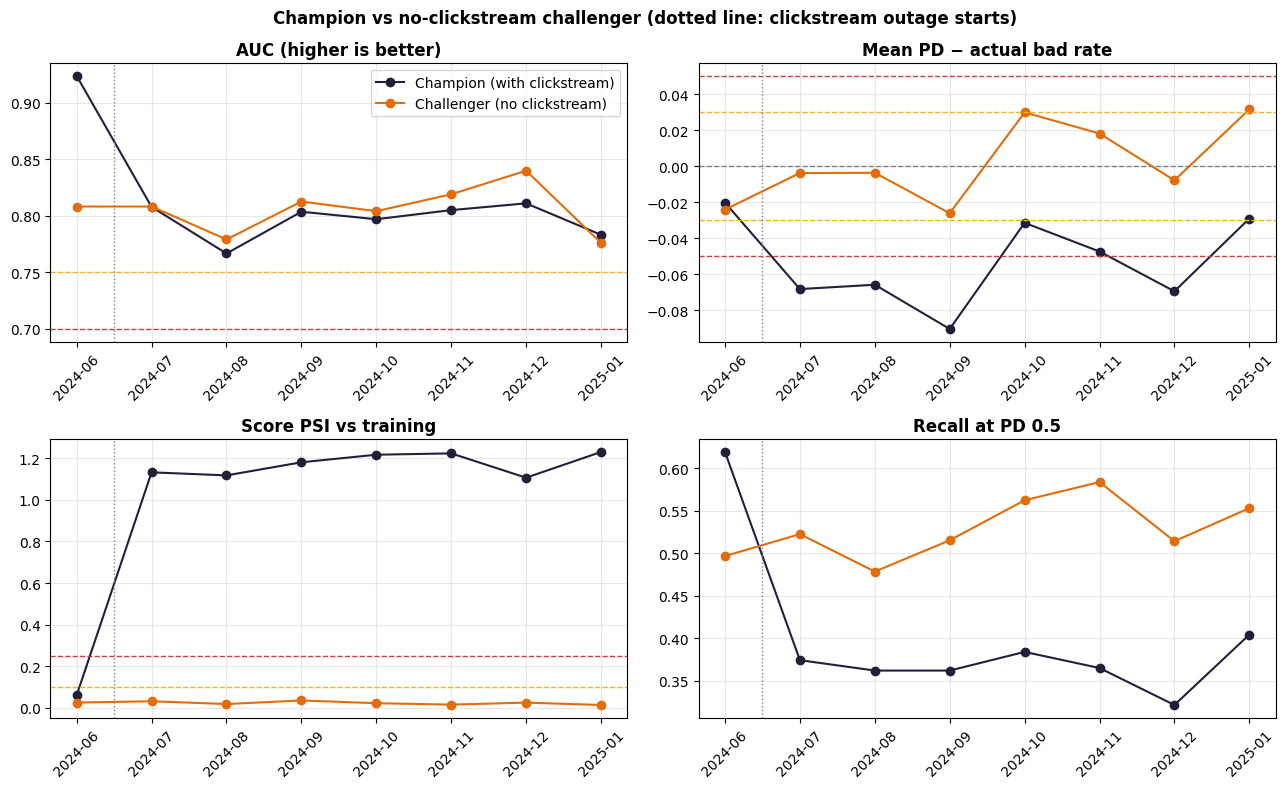

In [8]:
COLORS = {"champion": "#251E3B", "challenger": "#E46C0A"}
LABELS = {"champion": "Champion (with clickstream)", "challenger": "Challenger (no clickstream)"}
panels = [("auc", "AUC (higher is better)", [(0.75, "#fab219"), (0.70, "#d03b3b")]),
          ("gap", "Mean PD − actual bad rate", [(-0.03, "#fab219"), (-0.05, "#d03b3b"), (0.03, "#fab219"), (0.05, "#d03b3b"), (0, "grey")]),
          ("psi", "Score PSI vs training", [(0.10, "#fab219"), (0.25, "#d03b3b")]),
          ("recall@0.5", "Recall at PD 0.5", [])]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (metric, title, lines) in zip(axes.flat, panels):
    for m in ["champion", "challenger"]:
        d = monthly[monthly["model"] == m]
        ax.plot(d["month"], d[metric], marker="o", color=COLORS[m], label=LABELS[m])
    for y, c in lines:
        ax.axhline(y, color=c, linestyle="--", linewidth=1)
    ax.axvline(0.5, color="grey", linestyle=":", linewidth=1)  # clickstream stops after 2024-06
    ax.set_title(title, fontweight="bold")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle("Champion vs no-clickstream challenger (dotted line: clickstream outage starts)", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Conclusion

| | Champion (62) | Challenger (42, no clickstream) |
|---|---|---|
| OOT AUC (at training date) | **0.882** | 0.790 |
| Outage period AUC (2024-07..2025-01, 3,526 loans) | 0.796 | 0.805 (± 0.009 SE) |
| Mean PD − actual bad rate | −0.058 (red) | **+0.005 (green)** |
| Recall at PD 0.5 | 0.37 | **0.53** |
| Score PSI | 1.15 (red) | **0.01 (green)** |

1. **The champion was the right choice on 1 Jun 2024.** With clickstream available, it beats the challenger by 0.09 OOT AUC (about 8 standard errors). Clickstream carried real signal.
2. **During the outage, ranking is about the same.** The challenger's AUC is only 0.009 higher (about 1 SE), so the outage did not destroy the champion's ability to rank applicants.
3. **The damage is calibration, not ranking.** Missing clickstream gets imputed with training medians, which shifts the champion's scores down: PD is 3–9 points too low, and recall at 0.5 falls to 0.37. The challenger never saw clickstream, so its PDs stay calibrated (gap +0.005), its PSI stays green, and it catches 53% of defaulters at the 0.5 cutoff.
4. **Recommendation (governance, slide 10):** while the feed is down, **shadow → canary → promote the challenger** for applicants without clickstream. Keep the champion in the model bank and switch back once the feed is restored and validated. Recalibrating the champion instead would need 6 months of new labels; the challenger fixes calibration from day one.